# 01 — Exploring NYC TLC trip data

Goal: understand the raw data before designing the pipeline. Every check here ends up as either a
**schema contract** (types we enforce at ingestion) or a **quality rule** (rows we quarantine).

Data in `data/raw/` (download with `ingestion/download.py`):
- Yellow taxi: 2015-01, 2019-01, 2024-01 (to see schema drift across the years)
- HVFHV (Uber/Lyft/Via): 2024-01
- Taxi zone lookup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

RAW = Path("../data/raw").resolve()

spark = (
    SparkSession.builder.appName("nyc-taxi-explore")
    .master("local[*]")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.session.timeZone", "America/New_York")
    .config("spark.sql.shuffle.partitions", "16")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark.version

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/23 23:38:13 WARN Utils: Your hostname, MacBook-Pro-de-Merouane.local, resolves to a loopback address: 127.0.0.1; using 172.20.10.11 instead (on interface en0)
26/10/23 23:38:13 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/23 23:38:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'4.2.0'

## 1. Schema drift across years

If the schema were stable we could read all yellow files with one `spark.read.parquet(...)` call.
Let's compare column names and types per year.

In [2]:
yellow_files = sorted((RAW / "yellow").glob("*.parquet"))
schemas = {f.stem[-7:]: {fld.name: fld.dataType.simpleString() for fld in spark.read.parquet(str(f)).schema} for f in yellow_files}

all_cols = sorted({c for s in schemas.values() for c in s}, key=str.lower)
drift = spark.createDataFrame(
    [(c, *[schemas[m].get(c, "-") for m in schemas]) for c in all_cols],
    ["column", *schemas.keys()],
)
drift.show(len(all_cols), truncate=False)

+---------------------+-------------+-------------+-------------+
|column               |2015-01      |2019-01      |2024-01      |
+---------------------+-------------+-------------+-------------+
|airport_fee          |int          |int          |-            |
|Airport_fee          |-            |-            |double       |
|congestion_surcharge |int          |double       |double       |
|DOLocationID         |bigint       |bigint       |int          |
|extra                |double       |double       |double       |
|fare_amount          |double       |double       |double       |
|improvement_surcharge|double       |double       |double       |
|mta_tax              |double       |double       |double       |
|passenger_count      |bigint       |double       |bigint       |
|payment_type         |bigint       |bigint       |bigint       |
|PULocationID         |bigint       |bigint       |int          |
|RatecodeID           |bigint       |double       |bigint       |
|store_and

In [3]:
# What happens if we naively read every year together?
try:
    spark.read.option("mergeSchema", "true").parquet(*map(str, yellow_files)).count()
    print("merged OK")
except Exception as e:
    msg = next((l for l in str(e).splitlines() if "Exception" in l and "Py4J" not in l), str(e).splitlines()[0])
    print(type(e).__name__, "->", msg.strip()[:400])

Py4JJavaError -> : org.apache.spark.SparkException: [CANNOT_MERGE_SCHEMAS] Failed merging schemas:


## 2. Yellow taxi, January 2024 — profile

In [4]:
yellow = spark.read.parquet(str(RAW / "yellow" / "yellow_tripdata_2024-01.parquet"))
yellow = yellow.withColumnRenamed("Airport_fee", "airport_fee").cache()
n_yellow = yellow.count()
print(f"{n_yellow:,} rows, {len(yellow.columns)} columns")
yellow.printSchema()

2,964,624 rows, 19 columns
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)



In [5]:
# Null count per column
yellow.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in yellow.columns]).toPandas().T.rename(columns={0: "nulls"}).query("nulls > 0")

,nulls
passenger_count,140162
RatecodeID,140162
store_and_fwd_flag,140162
congestion_surcharge,140162
airport_fee,140162


In [6]:
num_cols = ["passenger_count", "trip_distance", "fare_amount", "tip_amount", "tolls_amount", "total_amount", "extra", "mta_tax", "improvement_surcharge", "congestion_surcharge", "airport_fee"]
yellow.select(num_cols).summary("min", "1%", "50%", "99%", "max", "mean").toPandas().set_index("summary").T

summary,min,1%,50%,99%,max,mean
passenger_count,0,0,1,5,9,1.3392808966805005
trip_distance,0.0,0.0,1.68,20.0,312722.3,3.6521691789583146
fare_amount,-899.0,-5.1,12.8,76.2,5000.0,18.175061916791037
tip_amount,-80.0,0.0,2.7,17.31,428.0,3.3358700158940002
tolls_amount,-80.0,0.0,0.0,6.94,115.92,0.5270212040378977
total_amount,-900.0,-9.5,20.1,103.36,5000.0,26.801504770952707
extra,-7.5,0.0,1.0,7.5,14.25,1.4515984320439959
mta_tax,-0.5,-0.5,0.5,0.5,4.0,0.4833823108765226
improvement_surcharge,-1.0,-1.0,1.0,1.0,1.0,0.9756318507844561
congestion_surcharge,-2.5,-2.5,2.5,2.5,2.5,2.2561220508542865


In [7]:
# Categorical codes: do they match the data dictionary?
for c in ["VendorID", "RatecodeID", "payment_type", "store_and_fwd_flag", "passenger_count"]:
    print(c, yellow.groupBy(c).count().orderBy(c).toPandas().values.tolist())

VendorID [[1, 729732], [2, 2234632], [6, 260]]


RatecodeID [[nan, 140162.0], [1.0, 2663350.0], [2.0, 98713.0], [3.0, 7954.0], [4.0, 6365.0], [5.0, 19410.0], [6.0, 7.0], [99.0, 28663.0]]
payment_type [[0, 140162], [1, 2319046], [2, 439191], [3, 19597], [4, 46628]]


store_and_fwd_flag [[None, 140162], ['N', 2813126], ['Y', 11336]]
passenger_count [[nan, 140162.0], [0.0, 31465.0], [1.0, 2188739.0], [2.0, 405103.0], [3.0, 91262.0], [4.0, 51974.0], [5.0, 33506.0], [6.0, 22353.0], [7.0, 8.0], [8.0, 51.0], [9.0, 1.0]]


In [8]:
# Timestamps: anything outside the file's month? Durations?
duration_min = (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60
y = yellow.withColumn("duration_min", duration_min)
y.select(
    F.min("tpep_pickup_datetime").alias("min_pickup"),
    F.max("tpep_pickup_datetime").alias("max_pickup"),
    F.sum((F.date_format("tpep_pickup_datetime", "yyyy-MM") != "2024-01").cast("int")).alias("pickup_outside_month"),
    F.sum((F.col("duration_min") < 0).cast("int")).alias("negative_duration"),
    F.sum((F.col("duration_min") == 0).cast("int")).alias("zero_duration"),
    F.sum((F.col("duration_min") > 180).cast("int")).alias("over_3h"),
).show(truncate=False)
y.select(F.percentile_approx("duration_min", [0.01, 0.5, 0.99]).alias("duration_p1_p50_p99")).show(truncate=False)

+-------------------+-------------------+--------------------+-----------------+-------------+-------+
|min_pickup         |max_pickup         |pickup_outside_month|negative_duration|zero_duration|over_3h|
+-------------------+-------------------+--------------------+-----------------+-------------+-------+
|2002-12-31 22:59:39|2024-02-01 00:01:15|18                  |56               |814          |1983   |
+-------------------+-------------------+--------------------+-----------------+-------------+-------+



+----------------------------------------------+
|duration_p1_p50_p99                           |
+----------------------------------------------+
|[0.6166666666666667, 11.633333333333333, 60.4]|
+----------------------------------------------+



In [9]:
# Does total_amount equal the sum of its parts?
parts = ["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount", "improvement_surcharge", "congestion_surcharge", "airport_fee"]
gap = F.abs(F.col("total_amount") - sum(F.coalesce(F.col(p), F.lit(0.0)) for p in parts))
yellow.select(
    F.sum((gap > 0.01).cast("int")).alias("total_mismatch"),
    F.percentile_approx(gap, [0.5, 0.99, 0.999]).alias("gap_p50_p99_p999"),
).show(truncate=False)

+--------------+------------------------------+
|total_mismatch|gap_p50_p99_p999              |
+--------------+------------------------------+
|761838        |[0.0, 2.500000000000007, 4.25]|
+--------------+------------------------------+



In [10]:
# Where does the mismatch come from? Break it down by vendor and the most common gap values.
yellow.withColumn("gap", F.round(F.col("total_amount") - sum(F.coalesce(F.col(p), F.lit(0.0)) for p in parts), 2)) \
    .filter(F.abs("gap") > 0.01).groupBy("VendorID", "gap").count().orderBy(F.desc("count")).show(8)
yellow.groupBy("VendorID").agg(F.count("*").alias("trips"), F.sum((gap > 0.01).cast("int")).alias("mismatch")).orderBy("VendorID").show()

+--------+-----+------+
|VendorID|  gap| count|
+--------+-----+------+
|       1| -2.5|590940|
|       2|  2.5| 85690|
|       1|  2.5| 43642|
|       1|-4.25| 22451|
|       1|-1.75| 18086|
|       1|  4.5|   792|
|       2| -2.5|   105|
|       2|-1.75|    63|
+--------+-----+------+
only showing top 8 rows


+--------+-------+--------+
|VendorID|  trips|mismatch|
+--------+-------+--------+
|       1| 729732|  675956|
|       2|2234632|   85882|
|       6|    260|       0|
+--------+-------+--------+



In [11]:
# The 140k rows with nulls: is it one population? (same rows null in every column?)
nullish = yellow.filter(F.col("passenger_count").isNull())
nullish.groupBy("VendorID", "payment_type").count().show()
nullish.select("fare_amount", "trip_distance", "total_amount").summary("min", "50%", "max").show()

+--------+------------+-----+
|VendorID|payment_type|count|
+--------+------------+-----+
|       2|           0|91447|
|       1|           0|48455|
|       6|           0|  260|
+--------+------------+-----+



+-------+-----------+-------------+------------+
|summary|fare_amount|trip_distance|total_amount|
+-------+-----------+-------------+------------+
|    min|     -67.15|          0.0|      -54.13|
|    50%|      16.82|         1.95|       21.86|
|    max|     298.61|     312722.3|      312.99|
+-------+-----------+-------------+------------+



In [12]:
# Negative fares: refunds/voids that mirror a real trip? Look for a positive twin with the same
# vendor, timestamps and locations.
key = ["VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID"]
neg = yellow.filter(F.col("total_amount") < 0).select(*key, F.col("total_amount").alias("neg_total"))
pos = yellow.filter(F.col("total_amount") > 0).select(*key, F.col("total_amount").alias("pos_total"))
twins = neg.join(pos, key)
print("negative rows:", neg.count(), "| with a positive twin:", twins.select(*key).distinct().count(),
      "| twin totals cancel out:", twins.filter(F.abs(F.col("neg_total") + F.col("pos_total")) < 0.01).count())

negative rows: 35504 | with a positive twin: 31101 | twin totals cancel out: 30676


In [13]:
# Tips are only recorded for card payments (payment_type = 1). Check that before analysing tipping.
yellow.groupBy("payment_type").agg(
    F.count("*").alias("trips"),
    F.round(F.avg("tip_amount"), 2).alias("avg_tip"),
    F.round(F.avg((F.col("tip_amount") > 0).cast("int")) * 100, 1).alias("pct_with_tip"),
).orderBy("payment_type").show()

+------------+-------+-------+------------+
|payment_type|  trips|avg_tip|pct_with_tip|
+------------+-------+-------+------------+
|           0| 140162|   1.55|        34.8|
|           1|2319046|   4.17|        95.1|
|           2| 439191|    0.0|         0.0|
|           3|  19597|   0.01|         0.5|
|           4|  46628|   0.04|         0.8|
+------------+-------+-------+------------+



## 3. Taxi zones — do all location IDs join?

In [14]:
zones = spark.read.option("header", True).option("inferSchema", True).csv(str(RAW / "taxi_zone_lookup.csv"))
print(zones.count(), "zones")
zones.groupBy("Borough").count().orderBy(F.desc("count")).show()
zones.filter(F.col("Zone").isNull() | F.col("Borough").isin("Unknown", "N/A")).show()

265 zones


+-------------+-----+
|      Borough|count|
+-------------+-----+
|    Manhattan|   69|
|       Queens|   69|
|     Brooklyn|   61|
|        Bronx|   43|
|Staten Island|   20|
|          EWR|    1|
|          N/A|    1|
|      Unknown|    1|
+-------------+-----+

+----------+-------+--------------+------------+
|LocationID|Borough|          Zone|service_zone|
+----------+-------+--------------+------------+
|       264|Unknown|           N/A|         N/A|
|       265|    N/A|Outside of NYC|         N/A|
+----------+-------+--------------+------------+



In [15]:
for side in ["PULocationID", "DOLocationID"]:
    unmatched = yellow.join(zones, yellow[side] == zones.LocationID, "left_anti")
    print(side, "not in lookup:", unmatched.count(),
          "| unknown zones 264/265:", yellow.filter(F.col(side).isin(264, 265)).count())

PULocationID not in lookup: 0 | unknown zones 264/265: 12018
DOLocationID not in lookup: 0 | unknown zones 264/265: 28083


In [16]:
# 264 = Unknown, 265 = Outside of NYC. Only 264 is really "unknown"; 265 is a valid out-of-city trip.
def zone_split(df, name):
    return (df.select(F.lit(name).alias("service"), F.explode(F.array(
                F.struct(F.lit("pickup").alias("side"), F.col("PULocationID").alias("zone")),
                F.struct(F.lit("dropoff").alias("side"), F.col("DOLocationID").alias("zone")))).alias("s"))
              .select("service", "s.*").filter(F.col("zone").isin(264, 265))
              .groupBy("service", "side").pivot("zone", [264, 265]).count())
zone_split(yellow, "yellow").show()

+-------+-------+-----+-----+
|service|   side|  264|  265|
+-------+-------+-----+-----+
| yellow| pickup|10360| 1658|
| yellow|dropoff|16116|11967|
+-------+-------+-----+-----+



## 4. HVFHV (Uber/Lyft), January 2024 — profile

In [17]:
fhvhv = spark.read.parquet(str(RAW / "fhvhv" / "fhvhv_tripdata_2024-01.parquet")).cache()
n_fhvhv = fhvhv.count()
print(f"{n_fhvhv:,} rows — {n_fhvhv / n_yellow:.1f}x yellow")
# HV0002=Juno, HV0003=Uber, HV0004=Via, HV0005=Lyft (TLC data dictionary)
fhvhv.groupBy("hvfhs_license_num").count().orderBy(F.desc("count")).show()

19,663,930 rows — 6.6x yellow


+-----------------+--------+
|hvfhs_license_num|   count|
+-----------------+--------+
|           HV0003|14432755|
|           HV0005| 5231175|
+-----------------+--------+



In [18]:
fhvhv.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in fhvhv.columns]).toPandas().T.rename(columns={0: "nulls"}).query("nulls > 0")

,nulls
originating_base_num,5218737
on_scene_datetime,5218737


In [19]:
fhv_num = ["trip_miles", "trip_time", "base_passenger_fare", "tolls", "bcf", "sales_tax", "congestion_surcharge", "airport_fee", "tips", "driver_pay"]
fhvhv.select(fhv_num).summary("min", "1%", "50%", "99%", "max", "mean").toPandas().set_index("summary").T

summary,min,1%,50%,99%,max,mean
trip_miles,0.0,0.47,2.83,26.39,417.62,4.838586508088679
trip_time,0,191,912,3793,52060,1110.4697250244483
base_passenger_fare,-43.09,7.15,18.01,104.85,1911.16,23.959245862337742
tolls,0.0,0.0,0.0,21.0,141.02,1.055207362411967
bcf,0.0,0.19,0.5,3.24,53.94,0.6905130388482664
sales_tax,0.0,0.0,1.53,8.48,152.69,2.0261249648483517
congestion_surcharge,0.0,0.0,0.0,2.75,8.25,1.075129412075816
airport_fee,0.0,0.0,0.0,2.5,6.9,0.19222517828328314
tips,0.0,0.0,0.0,14.83,196.8,1.0582556976146813
driver_pay,-67.76,5.39,13.57,74.81,1218.17,18.269094473973595


In [20]:
f = fhvhv.withColumn("computed_s", F.unix_timestamp("dropoff_datetime") - F.unix_timestamp("pickup_datetime"))
f.select(
    F.sum((F.date_format("pickup_datetime", "yyyy-MM") != "2024-01").cast("int")).alias("pickup_outside_month"),
    F.sum((F.col("dropoff_datetime") < F.col("pickup_datetime")).cast("int")).alias("negative_duration"),
    F.sum((F.abs(F.col("computed_s") - F.col("trip_time")) > 60).cast("int")).alias("trip_time_off_by_1min"),
    F.sum((F.col("request_datetime") > F.col("pickup_datetime")).cast("int")).alias("request_after_pickup"),
    F.sum((F.col("base_passenger_fare") <= 0).cast("int")).alias("fare_le_0"),
    F.sum((F.col("driver_pay") < 0).cast("int")).alias("driver_pay_lt_0"),
    F.sum((F.col("trip_miles") <= 0).cast("int")).alias("miles_le_0"),
).show(truncate=False)

+--------------------+-----------------+---------------------+--------------------+---------+---------------+----------+
|pickup_outside_month|negative_duration|trip_time_off_by_1min|request_after_pickup|fare_le_0|driver_pay_lt_0|miles_le_0|
+--------------------+-----------------+---------------------+--------------------+---------+---------------+----------+
|0                   |0                |0                    |188251              |7334     |137            |3286      |
+--------------------+-----------------+---------------------+--------------------+---------+---------------+----------+



In [21]:
zone_split(fhvhv, "hvfhv").show()
# Are the on_scene/originating_base nulls one company?
fhvhv.groupBy("hvfhs_license_num").agg(F.count("*").alias("trips"),
    F.sum(F.col("on_scene_datetime").isNull().cast("int")).alias("on_scene_null")).show()

+-------+-------+----+------+
|service|   side| 264|   265|
+-------+-------+----+------+
|  hvfhv|dropoff|NULL|741161|
|  hvfhv| pickup|NULL|   765|
+-------+-------+----+------+



+-----------------+--------+-------------+
|hvfhs_license_num|   trips|on_scene_null|
+-----------------+--------+-------------+
|           HV0005| 5231175|      5218737|
|           HV0003|14432755|            0|
+-----------------+--------+-------------+



## 5. Quality rules — how many rows would each one quarantine?

Candidate rules derived from the checks above. Rules are expressed as *"row is bad if…"* and a row
can break several. The thresholds are judgement calls, which is why we measure them before choosing.

In [22]:
YELLOW_RULES = {
    "pickup_outside_month": F.date_format("tpep_pickup_datetime", "yyyy-MM") != "2024-01",
    "dropoff_before_pickup": F.col("tpep_dropoff_datetime") < F.col("tpep_pickup_datetime"),
    "duration_over_6h": (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) > 6 * 3600,
    "distance_le_0": F.col("trip_distance") <= 0,
    "distance_over_200mi": F.col("trip_distance") > 200,
    "fare_lt_0": F.col("fare_amount") < 0,
    "total_lt_0": F.col("total_amount") < 0,
    "fare_over_1000": F.col("fare_amount") > 1000,
    "unknown_location": (F.col("PULocationID") == 264) | (F.col("DOLocationID") == 264),
}
FHVHV_RULES = {
    "pickup_outside_month": F.date_format("pickup_datetime", "yyyy-MM") != "2024-01",
    "dropoff_before_pickup": F.col("dropoff_datetime") < F.col("pickup_datetime"),
    "duration_over_6h": F.col("trip_time") > 6 * 3600,
    "distance_le_0": F.col("trip_miles") <= 0,
    "distance_over_200mi": F.col("trip_miles") > 200,
    "fare_le_0": F.col("base_passenger_fare") <= 0,
    "fare_over_1000": F.col("base_passenger_fare") > 1000,
    "unknown_location": (F.col("PULocationID") == 264) | (F.col("DOLocationID") == 264),
}

def rule_report(df, rules, total):
    row = df.select([F.sum(F.coalesce(expr, F.lit(False)).cast("int")).alias(name) for name, expr in rules.items()]
                    + [F.sum(F.greatest(*[F.coalesce(e, F.lit(False)).cast("int") for e in rules.values()])).alias("ANY_RULE")]).first()
    return spark.createDataFrame([(k, v, round(100 * v / total, 3)) for k, v in row.asDict().items()], ["rule", "rows", "pct"])

print("Yellow 2024-01"); rule_report(yellow, YELLOW_RULES, n_yellow).show(truncate=False)
print("HVFHV 2024-01"); rule_report(fhvhv, FHVHV_RULES, n_fhvhv).show(truncate=False)

Yellow 2024-01


+---------------------+------+-----+
|rule                 |rows  |pct  |
+---------------------+------+-----+
|pickup_outside_month |18    |0.001|
|dropoff_before_pickup|56    |0.002|
|duration_over_6h     |1772  |0.06 |
|distance_le_0        |60371 |2.036|
|distance_over_200mi  |31    |0.001|
|fare_lt_0            |37448 |1.263|
|total_lt_0           |35504 |1.198|
|fare_over_1000       |7     |0.0  |
|unknown_location     |19095 |0.644|
|ANY_RULE             |113422|3.826|
+---------------------+------+-----+

HVFHV 2024-01


+---------------------+-----+-----+
|rule                 |rows |pct  |
+---------------------+-----+-----+
|pickup_outside_month |0    |0.0  |
|dropoff_before_pickup|0    |0.0  |
|duration_over_6h     |90   |0.0  |
|distance_le_0        |3286 |0.017|
|distance_over_200mi  |99   |0.001|
|fare_le_0            |7334 |0.037|
|fare_over_1000       |21   |0.0  |
|unknown_location     |0    |0.0  |
|ANY_RULE             |10796|0.055|
+---------------------+-----+-----+



## 6. First look at the business questions (clean rows only)

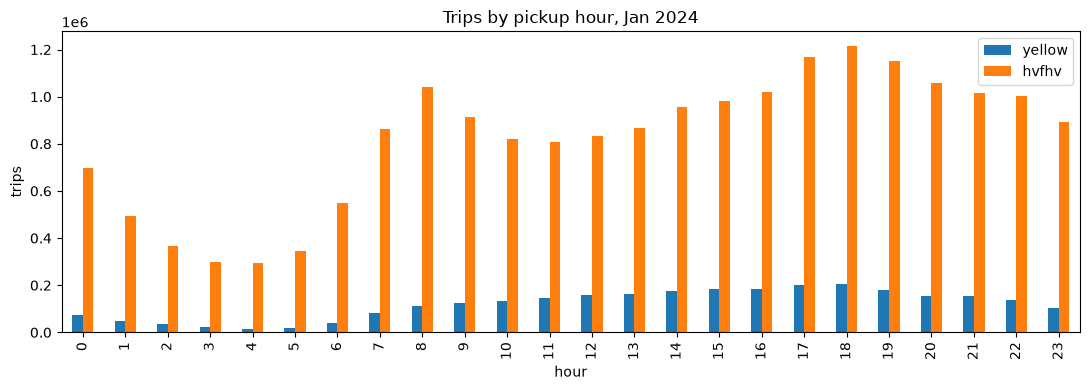

In [23]:
bad_yellow = F.greatest(*[F.coalesce(e, F.lit(False)).cast("int") for e in YELLOW_RULES.values()]) == 1
bad_fhvhv = F.greatest(*[F.coalesce(e, F.lit(False)).cast("int") for e in FHVHV_RULES.values()]) == 1
yc = yellow.filter(~bad_yellow)
fc = fhvhv.filter(~bad_fhvhv)

by_hour = (
    yc.groupBy(F.hour("tpep_pickup_datetime").alias("hour")).count().withColumnRenamed("count", "yellow")
    .join(fc.groupBy(F.hour("pickup_datetime").alias("hour")).count().withColumnRenamed("count", "hvfhv"), "hour")
    .orderBy("hour").toPandas().set_index("hour")
)
by_hour.plot(kind="bar", figsize=(11, 4), title="Trips by pickup hour, Jan 2024")
plt.ylabel("trips"); plt.tight_layout(); plt.show()

In [24]:
# Market share by pickup borough: where do yellow cabs still compete?
def by_borough(df, label):
    return df.join(zones, df.PULocationID == zones.LocationID).groupBy("Borough").count().withColumnRenamed("count", label)

share = (by_borough(yc, "yellow").join(by_borough(fc, "hvfhv"), "Borough", "outer").fillna(0)
         .withColumn("yellow_share_pct", F.round(100 * F.col("yellow") / (F.col("yellow") + F.col("hvfhv")), 1))
         .orderBy(F.desc("hvfhv")))
share.show()

+-------------+-------+-------+----------------+
|      Borough| yellow|  hvfhv|yellow_share_pct|
+-------------+-------+-------+----------------+
|    Manhattan|2565195|7859518|            24.6|
|     Brooklyn|  22245|5105463|             0.4|
|       Queens| 257215|4038340|             6.0|
|        Bronx|   5749|2367512|             0.2|
|Staten Island|     46| 281537|             0.0|
|          N/A|    702|    763|            47.9|
|          EWR|     50|      1|            98.0|
+-------------+-------+-------+----------------+



In [25]:
# Airport trips (JFK=132, LaGuardia=138, Newark=1) and tipping on card payments
airports = {1: "EWR", 132: "JFK", 138: "LGA"}
yc.filter(F.col("PULocationID").isin(*airports) | F.col("DOLocationID").isin(*airports)).agg(
    F.count("*").alias("yellow_airport_trips"),
    F.round(F.avg("total_amount"), 2).alias("avg_total"),
).show()
yc.filter((F.col("payment_type") == 1) & (F.col("fare_amount") > 0)).select(
    F.percentile_approx(F.col("tip_amount") / F.col("fare_amount") * 100, [0.25, 0.5, 0.75]).alias("tip_pct_p25_p50_p75")
).show(truncate=False)

+--------------------+---------+
|yellow_airport_trips|avg_total|
+--------------------+---------+
|              281986|    76.94|
+--------------------+---------+



+-----------------------------------------------------------+
|tip_pct_p25_p50_p75                                        |
+-----------------------------------------------------------+
|[20.735981308411215, 26.249999999999996, 31.11111111111111]|
+-----------------------------------------------------------+



## 7. Findings → decisions for the pipeline

### Schema contract (enforce at ingestion, before anything else)
| Finding | Evidence | Decision |
|---|---|---|
| Types drift between years: `passenger_count`/`RatecodeID` are bigint (2015, 2024) but double (2019); location IDs bigint → int in 2024 | §1 table | Cast every file to one pinned schema on read; never rely on `mergeSchema` |
| `mergeSchema` across years fails with `CANNOT_MERGE_SCHEMAS` | §1 | Process **one month per job**, cast, then append |
| `airport_fee` renamed to `Airport_fee` in 2024 | §1 | Normalise column names to snake_case lowercase |
| Columns that didn't exist yet (`congestion_surcharge` 2015, `airport_fee` ≤2019) come through as all-null | §1 | Keep them nullable in the contract |
| Timestamps are `timestamp_ntz` (NYC local time, no zone) | §2 schema | Store as local time + derive UTC explicitly |

### Quality rules (quarantine, don't delete)
| Rule | Yellow 2024-01 | HVFHV 2024-01 | Note |
|---|---|---|---|
| pickup outside the file's month | 18 (one from 2002) | 0 | |
| dropoff before pickup | 56 | 0 | |
| duration > 6 h | 1,772 | 90 | p99 is 60 min |
| distance ≤ 0 | 60,371 (2.0%) | 3,286 | biggest yellow rule |
| distance > 200 mi | 31 (max 312,722 mi) | 99 | |
| negative fare / total | ~35.5k (1.2%) | 7,334 fare ≤ 0 | see reversals below |
| fare > $1,000 | 7 | 21 | |
| pickup/dropoff in zone **264 (Unknown)** | 19,095 | 0 | |
| **any rule** | **113,422 (3.8%)** | **10,796 (0.06%)** | |

### Things that would have silently broken the analysis
1. **Zone 265 is "Outside of NYC", not unknown.** Treating 264 and 265 alike quarantined 741k Uber/Lyft trips (3.8%) that simply end in NJ/Westchester. Only 264 is a quality problem.
2. **Negative fares are reversals of real trips.** 31,101 of 35,504 negative-total rows have a positive twin with identical vendor, timestamps and zones, and 30,676 pairs cancel to $0.00. Dropping only the negative row leaves the voided trip counted → **quarantine both rows of a cancelling pair.**
3. **`total_amount` ≠ sum of components for 26% of yellow rows** — 93% of VendorID 1 trips, almost always by exactly −$2.50 / −$1.75 / −$4.25 (congestion and airport fee amounts). Vendor 1 appears to fold those surcharges into `extra`. → **Trust `total_amount`; never recompute it**, and don't analyse `extra` across vendors.
4. **140,162 yellow rows (4.7%) have `payment_type = 0`** and null passenger_count, RatecodeID, store_and_fwd_flag and both surcharges — one distinct population across all vendors (the newer TLC data dictionary lists code 0 as flex-fare trips). Keep them, but treat as their own category.
5. **Tips are only recorded for card payments**: cash tips are 0.0 by construction. Tip analysis = `payment_type = 1` only (median tip 26% of fare).
6. **`RatecodeID = 99`** (28,663 rows) isn't in the data dictionary → map to "unknown", don't quarantine.
7. **HVFHV**: only Uber (HV0003, 14.4M) and Lyft (HV0005, 5.2M) remain in 2024. `on_scene_datetime` / `originating_base_num` are null for Lyft only — a reporting difference, not bad data. 188k trips have `request_datetime` after pickup — kept, flagged for later.

### First answers
- Uber/Lyft did **6.6×** the trips of yellow cabs in Jan 2024.
- Yellow still holds **25%** of pickups in Manhattan and 6% in Queens (airports), but **<1%** in Brooklyn, the Bronx and Staten Island.
- 274k yellow trips touched an airport (EWR/JFK/LGA), averaging $75.62.

### Next step
Turn the schema contract and the rules above into a tested PySpark module (`spark_jobs/`) that writes `clean/` and `quarantine/` outputs per month.